
# Project I: Classifying Research Abstracts into Science, Business and Social Science
#DAC-515 Programming For Data Science
#Name: Mayank Tripathi
#Enrollment no. :26566009

**Goal:** read the abstract of a research paper and predict its field. We train and compare six classifiers:
Logistic Regression, Decision Tree, Naive Bayes, kNN, SVM and Random Forest.

**Steps**
1. Load the three Scopus CSV files and build one labelled dataset
2. Look at the data (class balance)
3. Clean the text (NLP preprocessing)
4. Split into train and test sets and convert text to numbers (TF-IDF)
5. Train the six models
6. Compare them (accuracy, precision, recall, F1, confusion matrices)
7. See which words matter
8. Save the best model and try the demo

## 1. Load the data and build the labelled dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import re

# Upload Science.csv, Business.csv and Social_Science.csv next to this notebook (Colab: /content)
science = pd.read_csv("/content/Science.csv.csv", encoding="utf-8-sig")
business = pd.read_csv("/content/Bussiness.csv.csv", encoding="utf-8-sig")
social = pd.read_csv("/content/Social_Science.csv.csv", encoding="utf-8-sig")

print("Science rows:", len(science))
print("Business rows:", len(business))
print("Social Science rows:", len(social))

Science rows: 600
Business rows: 600
Social Science rows: 600


In [3]:
# Keep only the columns we need
columns = ["Authors", "Title", "Year", "Abstract", "Link"]
science = science[columns].copy()
business = business[columns].copy()
social = social[columns].copy()

# Add the label (the class name) to each table
science["Label"] = "Science"
business["Label"] = "Business"
social["Label"] = "Social Science"

# Join the three tables into one
data = pd.concat([science, business, social], ignore_index=True)

# Remove rows with no abstract
data = data.dropna(subset=["Abstract"])

# Remove abstracts that appear more than once (keep=False removes ALL copies,
# which also removes abstracts that were found under two different labels)
data = data.drop_duplicates(subset="Abstract", keep=False)
data = data.reset_index(drop=True)

# Save the labelled dataset
data.to_csv("labelled_dataset.csv", index=False)
print("Total abstracts:", len(data))
data.head()

Total abstracts: 1760


,Authors,Title,Year,Abstract,Link,Label
0,Shao B.; Li J.; Zhang X.; Yang B.; Liu Z.; Wan...,INCARBench: A benchmark for scientific configu...,2027,Large language models (LLMs) are increasingly ...,https://www.scopus.com/pages/publications/1050...,Science
1,Tian D.; Shi M.; Zhang Z.; Li J.; Wu M.; Xu C....,Fluorescence aqueous detection of CO2 via prot...,2027,Carbon dioxide (CO2) concentration plays a cri...,https://www.scopus.com/pages/publications/1050...,Science
2,Khan S.B.; Lewis C.C.; Mudakala P.T.; Mintzer ...,Growing implementation scientists: NHLBI’s K12...,2026,Background: Implementation science seeks to ac...,https://www.scopus.com/pages/publications/1050...,Science
3,Mahdood B.; Merajikhah A.; Akbari Z.; Bastami ...,Surgical management and reconstruction techniq...,2026,Background: Divided eyelid nevus represents a ...,https://www.scopus.com/pages/publications/1050...,Science
4,Zhao L.; Zhao Y.; Qi Z.-B.; Li X.-Z.; Xiong L....,Granular Ta-Te nanowire superconductivity exce...,2026,Achieving higher upper-critical-field (μ0Hc2(0...,https://www.scopus.com/pages/publications/1050...,Science


## 2. Look at the data
The assignment asks for balanced classes, so first we count how many abstracts each class has.

Label
Business          598
Science           582
Social Science    580
Name: count, dtype: int64


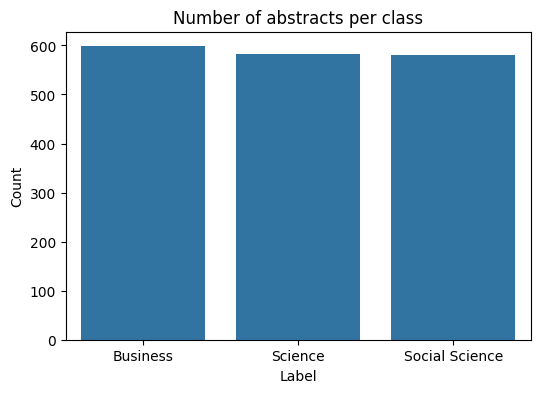

In [4]:
counts = data["Label"].value_counts()
print(counts)

plt.figure(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values)
plt.title("Number of abstracts per class")
plt.ylabel("Count")
plt.show()

if counts.min() < 0.5 * counts.max():
    print("WARNING: the classes are not balanced.")
    print("The small class will be hard to learn. Add more abstracts for it and run again.")

## 3. Clean the text (NLP preprocessing)
Steps for every abstract:
1. Cut off the copyright line (for example "© 2026 Elsevier"), because it tells us the publisher, not the topic
2. Make everything lowercase
3. Keep only letters (remove numbers and punctuation)
4. Split into words (tokenisation)
5. Remove stop words (the, of, and ...) and format words (background, methods ...)
6. Turn plurals into singular (studies to study, models to model)

**Important:** the abstracts were downloaded with keyword searches, so every Social Science abstract contains the word "social" and every Business abstract contains "business". If we kept those words, the models would just look for them instead of learning the field. So we add them to the stop-word list.

In [5]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Ready-made English stop words + our own extra words
extra_words = ["abstract", "background", "method", "methods", "result", "results",
               "conclusion", "conclusions", "objective", "aim", "purpose", "introduction",
               "paper", "study", "article", "research", "elsevier", "springer", "wiley",
               "copyright", "rights", "reserved", "author", "authors", "published", "license",
               "social", "business", "science"]       # <- the search keywords
stop_words = set(ENGLISH_STOP_WORDS) | set(extra_words)

def make_singular(word):
    if word.endswith("ies") and len(word) > 4:
        return word[:-3] + "y"          # studies -> study
    if word.endswith("s") and not word.endswith("ss") and not word.endswith("us"):
        return word[:-1]                # models -> model
    return word

def clean_text(text):
    text = str(text)
    text = text.split("©")[0]                    # 1. remove the copyright part
    text = text.lower()                          # 2. lowercase
    text = re.sub(r"[^a-z ]", " ", text)         # 3. keep only letters
    words = text.split()                         # 4. split into words
    good_words = []
    for word in words:
        word = make_singular(word)               # 6. singular form
        if word not in stop_words and len(word) > 2:   # 5. remove stop words
            good_words.append(word)
    return " ".join(good_words)

data["clean"] = data["Abstract"].apply(clean_text)

print("BEFORE:", data["Abstract"][0][:300])
print()
print("AFTER :", data["clean"][0][:300])

BEFORE: Large language models (LLMs) are increasingly being integrated into first-principles computational workflows, yet their ability to configure scientific calculations remains poorly understood. Here, we introduce INCARBench, a benchmark for evaluating LLMs on input configuration for the Vienna Ab init

AFTER : large language model llm increasingly integrated principle computational workflow ability configure scientific calculation remain poorly understood introduce incarbench benchmark evaluating llm input configuration vienna initio simulation package vasp configuration generation repair task evaluating 


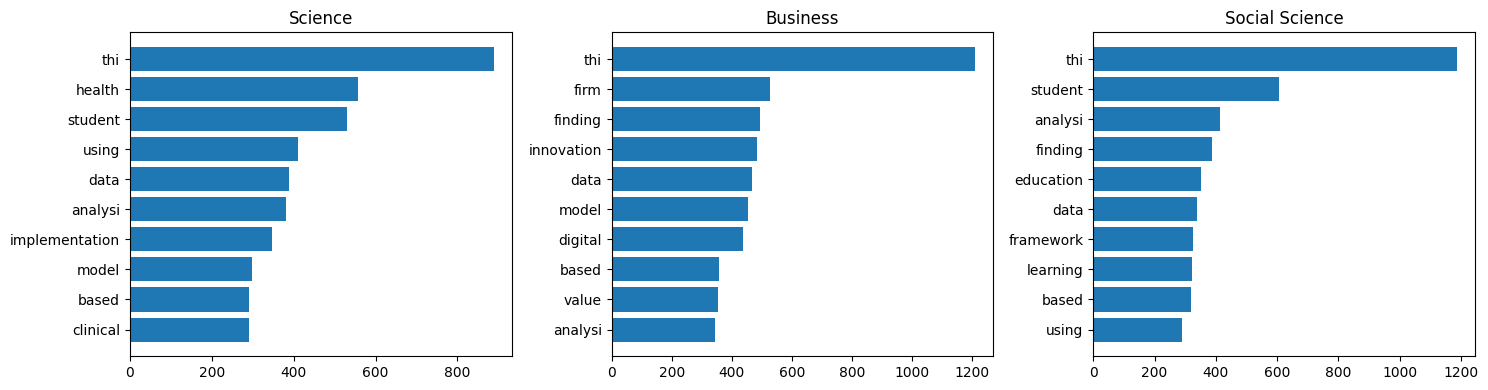

In [ ]:
# Most common words in each class
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, label in zip(axes, ["Science", "Business", "Social Science"]):
    text = " ".join(data[data["Label"] == label]["clean"])
    top_words = pd.Series(text.split()).value_counts().head(10)
    ax.barh(top_words.index[::-1], top_words.values[::-1])
    ax.set_title(label)
plt.tight_layout()
plt.show()

## 4. Train/test split and TF-IDF
* 80% of the abstracts are used for training and 20% for testing. `stratify` keeps the class proportions the same in both parts.
* Models need numbers, not words. **TF-IDF** turns every abstract into a list of numbers that show how important each word is.
* The TF-IDF is learned from the training data only (`fit_transform`); the test data only gets `transform`.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = data["clean"]
y = data["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training abstracts:", len(X_train))
print("Testing abstracts :", len(X_test))

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Matrix shape:", X_train_tfidf.shape)

Training abstracts: 1408
Testing abstracts : 352
Matrix shape: (1408, 5000)


## 5. Train the six models
`class_weight="balanced"` tells a model to pay more attention to small classes (Naive Bayes and kNN do not have this option).

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "Naive Bayes": MultinomialNB(),
    "kNN": KNeighborsClassifier(n_neighbors=5, metric="cosine"),
    "SVM": LinearSVC(class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42),
}

predictions = {}     # will store the predicted labels of every model
results = []         # will store the scores of every model

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)              # train
    y_pred = model.predict(X_test_tfidf)           # predict the test abstracts
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score": f1_score(y_test, y_pred, average="macro", zero_division=0),
    })
    print(name, "done")

results = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
results.round(3)

Logistic Regression done
Decision Tree done
Naive Bayes done
kNN done
SVM done
Random Forest done


,Model,Accuracy,Precision,Recall,F1-score
0,SVM,0.869,0.869,0.869,0.869
1,Logistic Regression,0.852,0.854,0.852,0.853
2,Naive Bayes,0.835,0.839,0.834,0.835
3,Random Forest,0.804,0.802,0.803,0.802
4,kNN,0.759,0.755,0.758,0.753
5,Decision Tree,0.676,0.679,0.675,0.677


In [8]:
# Precision, recall and F1 for every class and model
from sklearn.metrics import classification_report

for name, y_pred in predictions.items():
    print("=====", name, "=====")
    print(classification_report(y_test, y_pred, zero_division=0))

===== Logistic Regression =====
                precision    recall  f1-score   support

      Business       0.91      0.88      0.89       120
       Science       0.88      0.84      0.86       116
Social Science       0.78      0.83      0.80       116

      accuracy                           0.85       352
     macro avg       0.85      0.85      0.85       352
  weighted avg       0.85      0.85      0.85       352

===== Decision Tree =====
                precision    recall  f1-score   support

      Business       0.77      0.73      0.75       120
       Science       0.69      0.67      0.68       116
Social Science       0.58      0.62      0.60       116

      accuracy                           0.68       352
     macro avg       0.68      0.68      0.68       352
  weighted avg       0.68      0.68      0.68       352

===== Naive Bayes =====
                precision    recall  f1-score   support

      Business       0.87      0.91      0.89       120
       Science 

## 6. Compare the models
Precision, recall and F1 are **macro** averages: every class counts equally, so a model cannot look good by ignoring a small class.

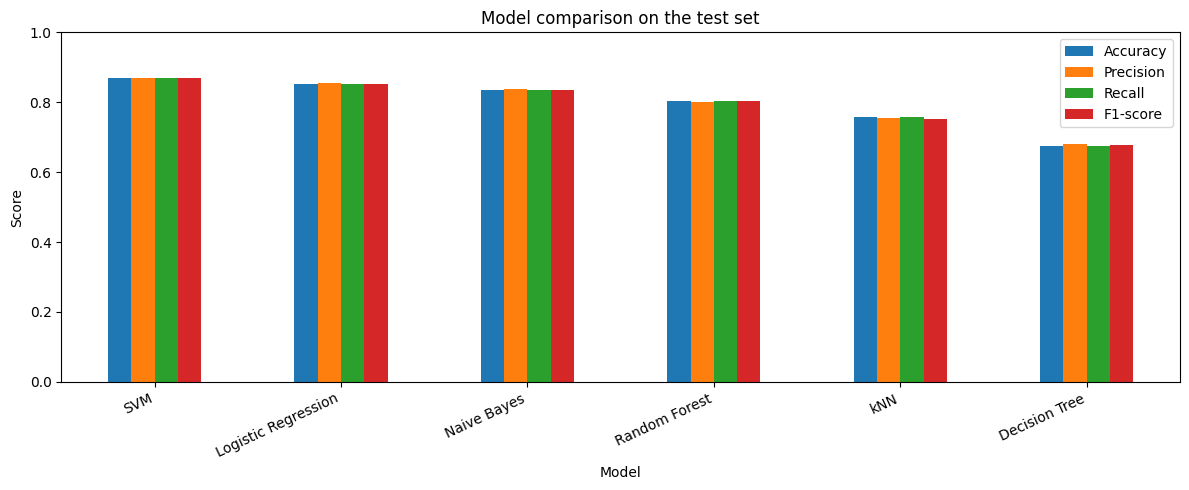

In [9]:
results_plot = results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]]
results_plot.plot(kind="bar", figsize=(12, 5))
plt.title("Model comparison on the test set")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

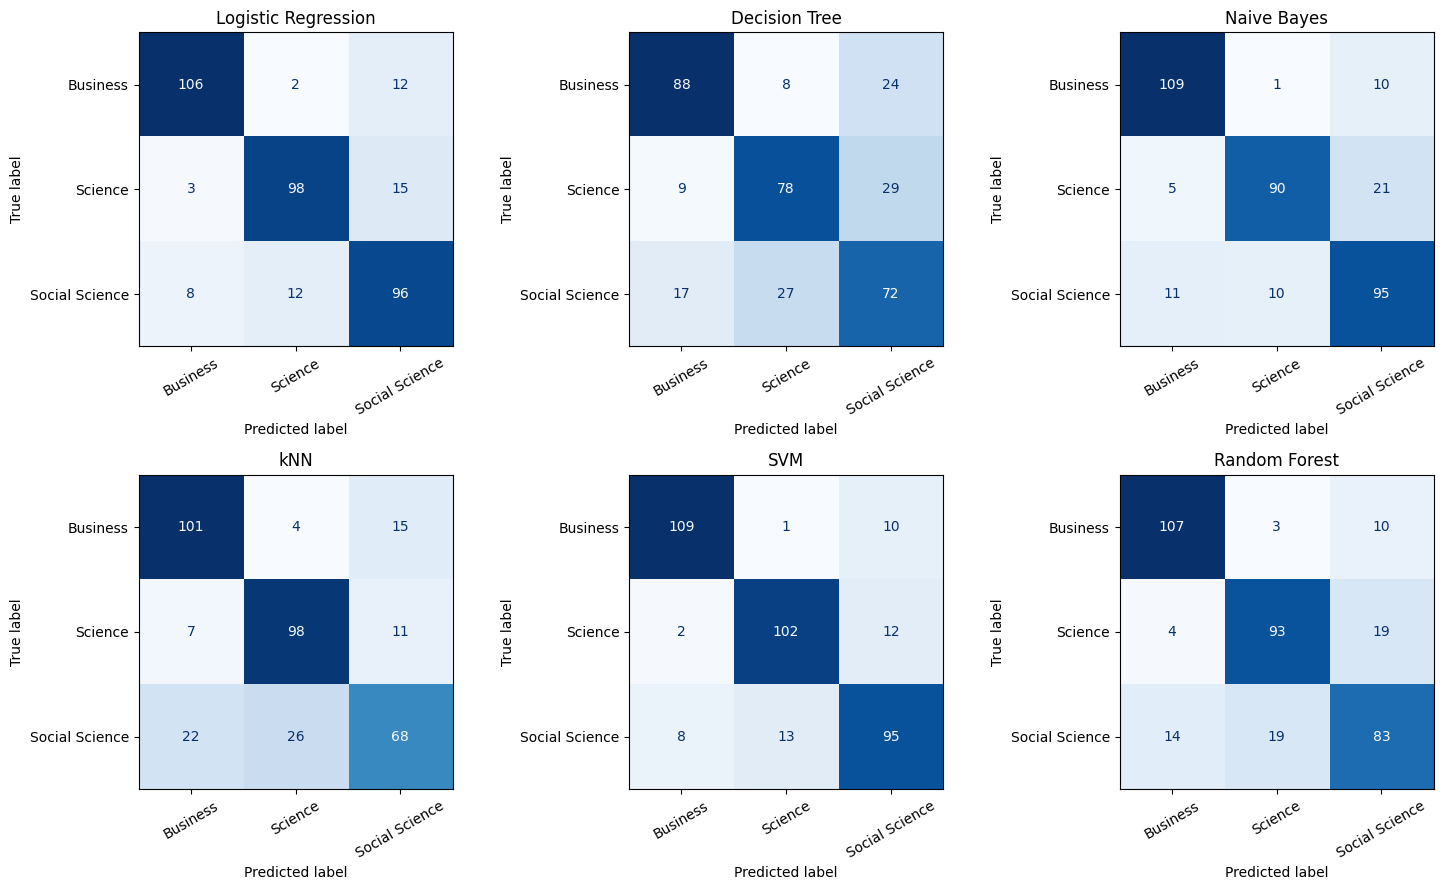

In [10]:
# Confusion matrices: rows = real class, columns = predicted class
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, y_pred) in zip(axes.flatten(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Comparison without the tiny Business class
If one class has only a few abstracts, the test set contains only one or two of them, so the scores above are unreliable. This cell repeats the experiment using only the two large classes, which gives a fairer comparison of the six algorithms. (If you add enough Business abstracts, you can ignore this cell.)

In [11]:
two = data[data["Label"] != "Business"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    two["clean"], two["Label"], test_size=0.2, random_state=42, stratify=two["Label"])

tfidf2 = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
X2_train_tfidf = tfidf2.fit_transform(X2_train)
X2_test_tfidf = tfidf2.transform(X2_test)

results2 = []
for name, model in models.items():
    model.fit(X2_train_tfidf, y2_train)
    y_pred = model.predict(X2_test_tfidf)
    results2.append({
        "Model": name,
        "Accuracy": accuracy_score(y2_test, y_pred),
        "Precision": precision_score(y2_test, y_pred, average="macro"),
        "Recall": recall_score(y2_test, y_pred, average="macro"),
        "F1-score": f1_score(y2_test, y_pred, average="macro"),
    })

results2 = pd.DataFrame(results2).sort_values("F1-score", ascending=False).reset_index(drop=True)
print("Science vs Social Science only:", len(two), "abstracts")
results2.round(3)

Science vs Social Science only: 1162 abstracts


,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.863,0.864,0.863,0.863
1,Logistic Regression,0.854,0.855,0.854,0.854
2,kNN,0.850,0.851,0.850,0.850
3,Naive Bayes,0.841,0.844,0.841,0.841
4,SVM,0.841,0.843,0.841,0.841
5,Decision Tree,0.700,0.701,0.699,0.699


In [12]:
# The models above were refitted on the two-class data, so train them again on all three classes
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
print("Models are trained on all three classes again")

Models are trained on all three classes again


## 7. Which words matter? (feature visualisation)
Logistic Regression gives every word a score for every class. The highest scores are the words that push an abstract towards that class. Random Forest tells us which words it used most.

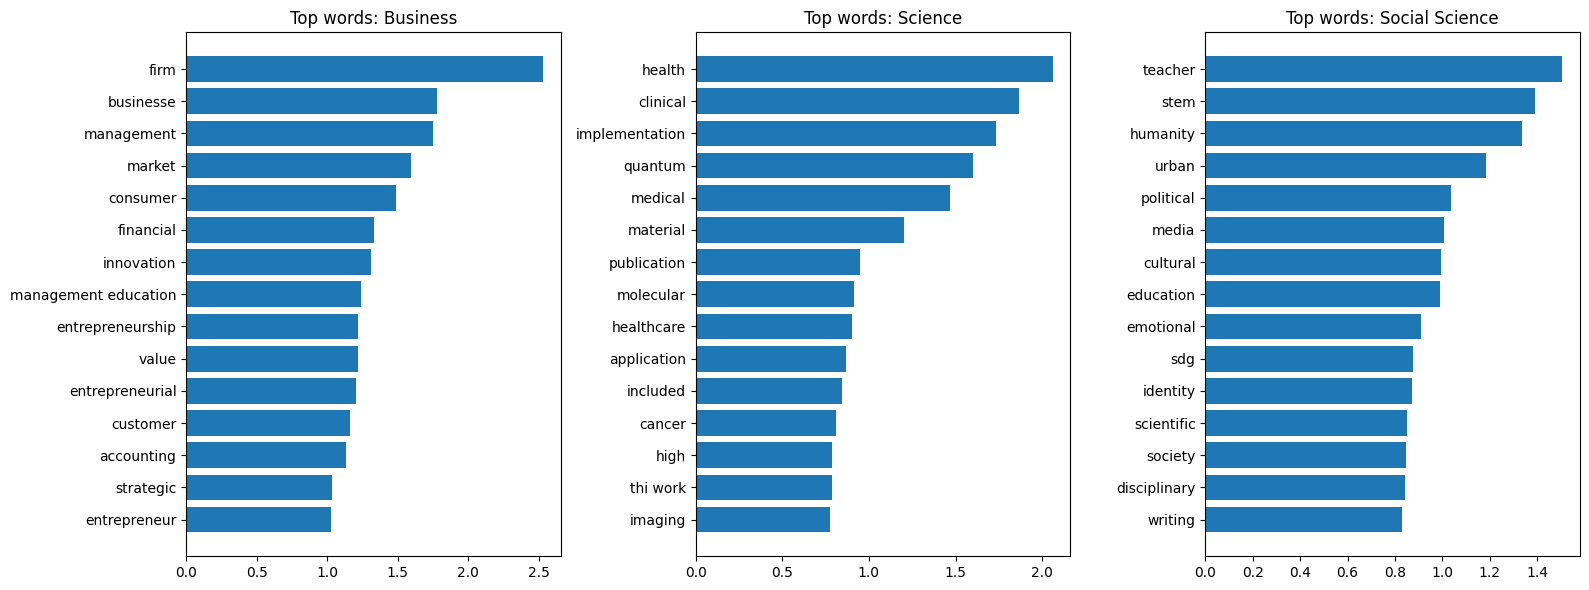

In [13]:
words = np.array(tfidf.get_feature_names_out())
lr = models["Logistic Regression"]

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, class_name, scores in zip(axes, lr.classes_, lr.coef_):
    best = np.argsort(scores)[-15:]          # positions of the 15 highest scores
    ax.barh(words[best], scores[best])
    ax.set_title("Top words: " + class_name)
plt.tight_layout()
plt.show()

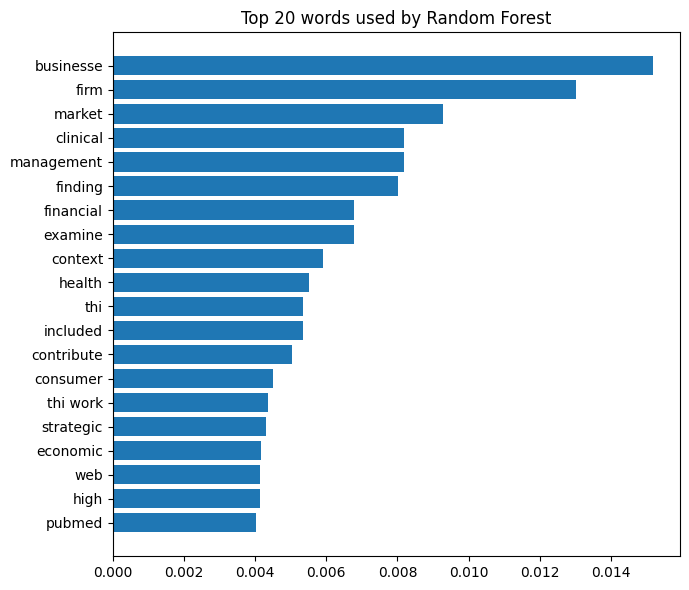

In [14]:
rf = models["Random Forest"]
best = np.argsort(rf.feature_importances_)[-20:]

plt.figure(figsize=(7, 6))
plt.barh(words[best], rf.feature_importances_[best])
plt.title("Top 20 words used by Random Forest")
plt.tight_layout()
plt.show()

## 8. Look at the mistakes of the best model

In [15]:
best_name = results.loc[0, "Model"]          # model with the highest accuracy
best_model = models[best_name]
print("Best model:", best_name)

y_pred = predictions[best_name]
mistakes = pd.DataFrame({
    "Title": data.loc[y_test.index, "Title"].str[:70],
    "Real": y_test,
    "Predicted": y_pred,
})
mistakes = mistakes[mistakes["Real"] != mistakes["Predicted"]]
print(len(mistakes), "wrong predictions out of", len(y_test))
mistakes.head(10)

Best model: SVM
46 wrong predictions out of 352


,Title,Real,Predicted
1257,Barriers to internationalisation of library sc...,Social Science,Science
1614,Social innovations in scientific communication...,Social Science,Science
11,The economics of implementing Magnet® designat...,Science,Business
1402,"Public health is already working with you, and...",Social Science,Science
1151,Digital twins for low-altitude transportation ...,Business,Science
921,Women’s empowerment and climate resilience: gl...,Business,Social Science
603,How do characteristic elements of public space...,Business,Social Science
1104,Curated well-being: entrepreneurship and place...,Business,Social Science
783,Duration matters: comparing learner engagement...,Business,Social Science
1242,Conceptual framework of social trust in AI-ena...,Social Science,Business


## 9. Save the best model

In [16]:
joblib.dump(best_model, "best_model.joblib")
joblib.dump(tfidf, "tfidf.joblib")
results.round(4).to_csv("model_comparison.csv", index=False)
print("Saved best_model.joblib, tfidf.joblib and model_comparison.csv")

Saved best_model.joblib, tfidf.joblib and model_comparison.csv


## 10. Demo: predict the field of new abstracts
New text goes through the same `clean_text()` and TF-IDF as the training data.

In [17]:
def predict_one(text):
    cleaned = clean_text(text)
    numbers = tfidf.transform([cleaned])
    return best_model.predict(numbers)[0]

abstract_1 = "Layered double hydroxide nanosheets were synthesised by a hydrothermal route and characterised by X-ray diffraction and electron microscopy. The catalyst showed high activity for electrochemical water splitting."
abstract_2 = "We study how remote work and school closures changed family routines, using interviews with parents and teachers in three cities."

print("Abstract 1 ->", predict_one(abstract_1))
print("Abstract 2 ->", predict_one(abstract_2))

Abstract 1 -> Science
Abstract 2 -> Social Science


In [18]:
# Predict labels for a whole CSV file (it needs a column called "Abstract")
def predict_csv(filename):
    new_data = pd.read_csv(filename, encoding="utf-8-sig")
    new_data["Predicted Label"] = new_data["Abstract"].fillna("").apply(predict_one)
    new_data.to_csv("predicted_labels.csv", index=False)
    return new_data

# Test with 20 abstracts taken from our own data (labels removed)
data[["Title", "Abstract"]].sample(20, random_state=1).to_csv("demo_input.csv", index=False)
demo_result = predict_csv("demo_input.csv")
demo_result[["Title", "Predicted Label"]].head(10)

,Title,Predicted Label
0,"Any old Tom, Dick, or Harry: The citation impa...",Social Science
1,“From stereotyping to stethoscope”: assessing ...,Social Science
2,RECORDS OF THE POOR: POSSIBILITIES FOR USING T...,Social Science
3,Institutional incentives and faculty cooperati...,Science
4,Does digital transformation exacerbate systemi...,Business
5,SocLitGen: An LLM-assisted framework for autom...,Social Science
6,Combining storylines of energy citizenship wit...,Social Science
7,Contextualized learning theory in practice: An...,Business
8,Rationality Meets Irrationality: Incentivizing...,Social Science
9,A PSYCHOLOGICAL EXPLANATION FOR REINSTATING PR...,Social Science


In [19]:
# Upload your own CSV (works in Google Colab)
try:
    from google.colab import files
    uploaded = files.upload()
    for filename in uploaded:
        result = predict_csv(filename)
        print(result["Predicted Label"].value_counts())
        files.download("predicted_labels.csv")
except ImportError:
    print("This cell works in Google Colab. On your own computer use predict_csv('yourfile.csv')")

KeyboardInterrupt: 